In [90]:
!pip install librosa

In [91]:
import os
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_io as tfio
from scipy.signal import resample_poly
import librosa

In [92]:
CAPUCHIN_FILE = os.path.join('data', 'Parsed_Capuchinbird_Clips', 'XC3776-3.wav')
NOT_CAPUCHIN_FILE = os.path.join('data', 'Parsed_Not_Capuchinbird_Clips', 'afternoon-birds-song-in-forest-0.wav')

In [93]:

# # Load an audio file
# samples, sample_rate = librosa.load(
#     CAPUCHIN_FILE,
#     sr=None
# )

# print(samples.shape)
# print(sample_rate)

In [94]:

# import tensorflow as tf
# from scipy.signal import resample_poly
# from math import gcd

# def load_wav_16k_mono(filename):
#     # Load encoded WAV file
#     file_contents = tf.io.read_file(filename)

#     # Decode WAV to mono
#     wav, sample_rate = tf.audio.decode_wav(
#         file_contents,
#         desired_channels=1
#     )

#     # Remove the channel dimension
#     wav = tf.squeeze(wav, axis=-1)

#     # Convert the sample rate to a Python integer
#     sample_rate = int(sample_rate.numpy())

#     # Resample audio to 16000 Hz
#     target_rate = 16000

#     if sample_rate != target_rate:
#         factor = gcd(sample_rate, target_rate)

#         wav = resample_poly(
#             wav.numpy(),
#             up=target_rate // factor,
#             down=sample_rate // factor
#         )

#         # Convert result back to TensorFlow tensor
#         wav = tf.convert_to_tensor(wav, dtype=tf.float32)

#     return wav


Standadiztion a audio


In [95]:
import librosa
import tensorflow as tf
import numpy as np

def load_wav_16k_mono(filename):

    # Convert TensorFlow tensor to NumPy
    if isinstance(filename, tf.Tensor):
        filename = filename.numpy()

    # Convert NumPy scalar array to Python value
    if isinstance(filename, np.ndarray):
        filename = filename.item()

    # Convert bytes to Python string
    if isinstance(filename, bytes):
        filename = filename.decode("utf-8")

    # Load audio using Librosa
    wav, sample_rate = librosa.load(
        filename,
        sr=16000,
        mono=True
    )

    return wav.astype(np.float32)


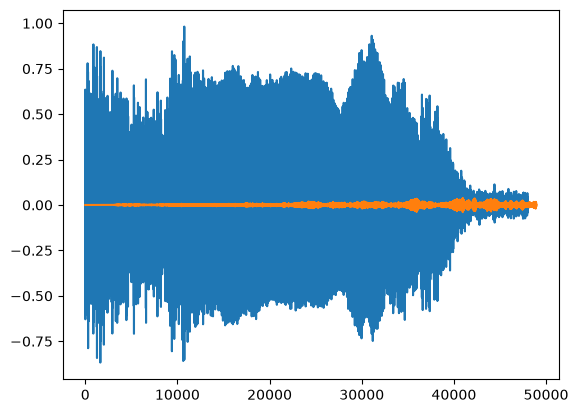

In [96]:
wave = load_wav_16k_mono(CAPUCHIN_FILE)
nwave = load_wav_16k_mono(NOT_CAPUCHIN_FILE)
plt.plot(wave)
plt.plot(nwave)
plt.show()

In [97]:
POS = os.path.join('data', 'Parsed_Capuchinbird_Clips')
NEG = os.path.join('data', 'Parsed_Not_Capuchinbird_Clips')

In [98]:
pos = tf.data.Dataset.list_files(POS+'\*.wav')
neg = tf.data.Dataset.list_files(NEG+'\*.wav')

3.3 Add labels and Combine Positive and Negative Samples

In [99]:
positives = tf.data.Dataset.zip((pos, tf.data.Dataset.from_tensor_slices(tf.ones(len(pos)))))
negatives = tf.data.Dataset.zip((neg, tf.data.Dataset.from_tensor_slices(tf.zeros(len(neg)))))
data = positives.concatenate(negatives)

In [100]:
lengths = []
for file in os.listdir(os.path.join('data', 'Parsed_Capuchinbird_Clips')):
    tensor_wave = load_wav_16k_mono(os.path.join('data', 'Parsed_Capuchinbird_Clips', file))
    lengths.append(len(tensor_wave))

In [101]:
tf.math.reduce_mean(lengths)

<tf.Tensor: shape=(), dtype=int32, numpy=54156>

In [102]:
tf.math.reduce_min(lengths)

<tf.Tensor: shape=(), dtype=int32, numpy=32000>

In [103]:
tf.math.reduce_max(lengths)

<tf.Tensor: shape=(), dtype=int32, numpy=80000>

In [104]:
def preprocess(file_path, label):

    # Execute Librosa loading through Python
    wav = tf.numpy_function(
        load_wav_16k_mono,
        [file_path],
        tf.float32
    )

    # Specify waveform shape
    wav.set_shape([None])

    # Keep only first 48000 samples
    wav = wav[:48000]

    # Calculate zero padding
    zero_padding = tf.zeros(
        [48000] - tf.shape(wav),
        dtype=tf.float32
    )

    # Add padding
    wav = tf.concat([zero_padding, wav], axis=0)

    # Generate spectrogram
    spectrogram = tf.signal.stft(
        wav,
        frame_length=320,
        frame_step=32
    )

    # Convert complex numbers to magnitude
    spectrogram = tf.abs(spectrogram)

    # Add channel dimension
    spectrogram = tf.expand_dims(
        spectrogram,
        axis=2
    )

    # Specify final shape
    spectrogram.set_shape([1491, 257, 1])

    return spectrogram, label

In [105]:
filepath, label = positives.shuffle(buffer_size=10000).as_numpy_iterator().next()

In [106]:
spectrogram, label = preprocess(filepath, label)

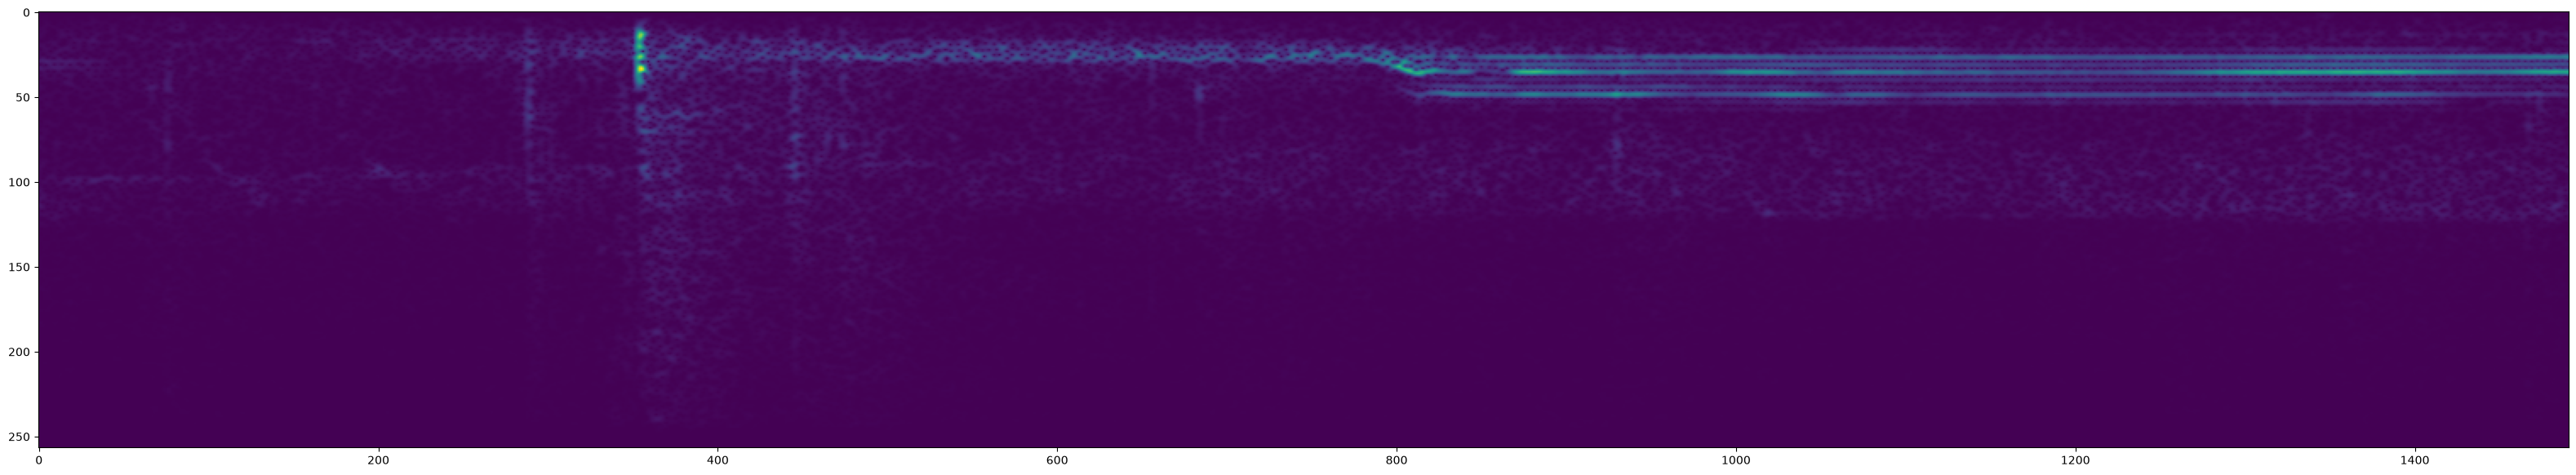

In [107]:
plt.figure(figsize=(40,20))
plt.imshow(tf.transpose(spectrogram)[0])
plt.show()

In [108]:
data = data.cache()
data = data.shuffle(buffer_size=1000)
data = data.batch(16)
data = data.prefetch(tf.data.AUTOTUNE)

train = data.take(36)
test = data.skip(36).take(15)

samples, labels = train.as_numpy_iterator().next()

In [109]:
train = data.take(36)
test = data.skip(36).take(15)

In [110]:
samples, labels = train.as_numpy_iterator().next()

In [111]:
samples.shape

(16,)

In [112]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, Dense, Flatten